# Core vs RoA/CRR

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

plt.rcParams["figure.dpi"] = 300

# Load parquet

In [16]:
path_roa = Path("/work/scratch-nopw2/mendrika/ASNIE/final-database/RoA/parquet")
path_crr = Path("/work/scratch-nopw2/mendrika/ASNIE/final-database/CRR/parquet")

cores = pd.read_parquet(path_roa / "core_thr_0p0.parquet")
roa = pd.read_parquet(path_roa / "roa_thr_4p886.parquet")
crr = pd.read_parquet(path_crr / "crr_thr_4p365.parquet")

t_end = crr["time"].max()

cores = cores[cores["time"] <= t_end]
roa = roa[roa["time"] <= t_end]

print("cores:", len(cores))
print("roa:", len(roa))
print("crr:", len(crr))

cores: 6277
roa: 127873
crr: 15727


In [17]:
print(cores.time.min(), cores.time.max())
print(roa.time.min(), roa.time.max())
print(crr.time.min(), crr.time.max())

2024-06-01 00:00:00 2024-08-05 14:00:00
2024-06-01 00:00:00 2024-08-05 14:00:00
2024-06-01 00:00:00 2024-08-05 14:00:00


# Compute distance

In [18]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres.

    This function applies a simple equirectangular projection to transform
    geographic coordinates (lat, lon) into planar (x, y) coordinates. The
    conversion is suitable for computing Euclidean distances between nearby
    points (e.g., storm-object centroids) over a limited geographic region.

    Longitude distances are scaled by cos(mean latitude) to account for the
    decrease in east–west distance away from the equator.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Array containing projected coordinates in kilometres, where each row
        corresponds to a point (x, y).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    x = R * lon_rad * np.cos(np.mean(lat_rad))                      # mean to make sure it's consistent across dataset (assuming a single reference latitude for simplicity)
    y = R * lat_rad

    return np.column_stack((x, y))

In [19]:
def core_to_rain_distances(df_core, df_rain, start_hour=12, end_hour=21):
    """
    Compute the distance from each core object to the nearest rainfall object
    at the same timestep, restricting the analysis to convectively active hours.
    """

    matches = []

    # Restrict to convectively active period
    core_active = df_core[(df_core["hour"] >= start_hour) & (df_core["hour"] <= end_hour)]
    rain_active = df_rain[(df_rain["hour"] >= start_hour) & (df_rain["hour"] <= end_hour)]

    for t, core_group in core_active.groupby("time"):

        rain_group = rain_active[rain_active["time"] == t]

        if len(core_group) == 0 or len(rain_group) == 0:
            continue

        rain_xy = latlon_to_xy_km(
            rain_group["lat_centroid"].values,
            rain_group["lon_centroid"].values
        )

        tree = cKDTree(rain_xy)

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        distances, _ = tree.query(core_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [20]:
dist_core_roa = core_to_rain_distances(cores, roa)
dist_core_crr = core_to_rain_distances(cores, crr)

In [21]:
print(np.mean(dist_core_roa <= 30))
print(np.mean(dist_core_crr <= 30))

0.02843966179861645
0.010158013544018058


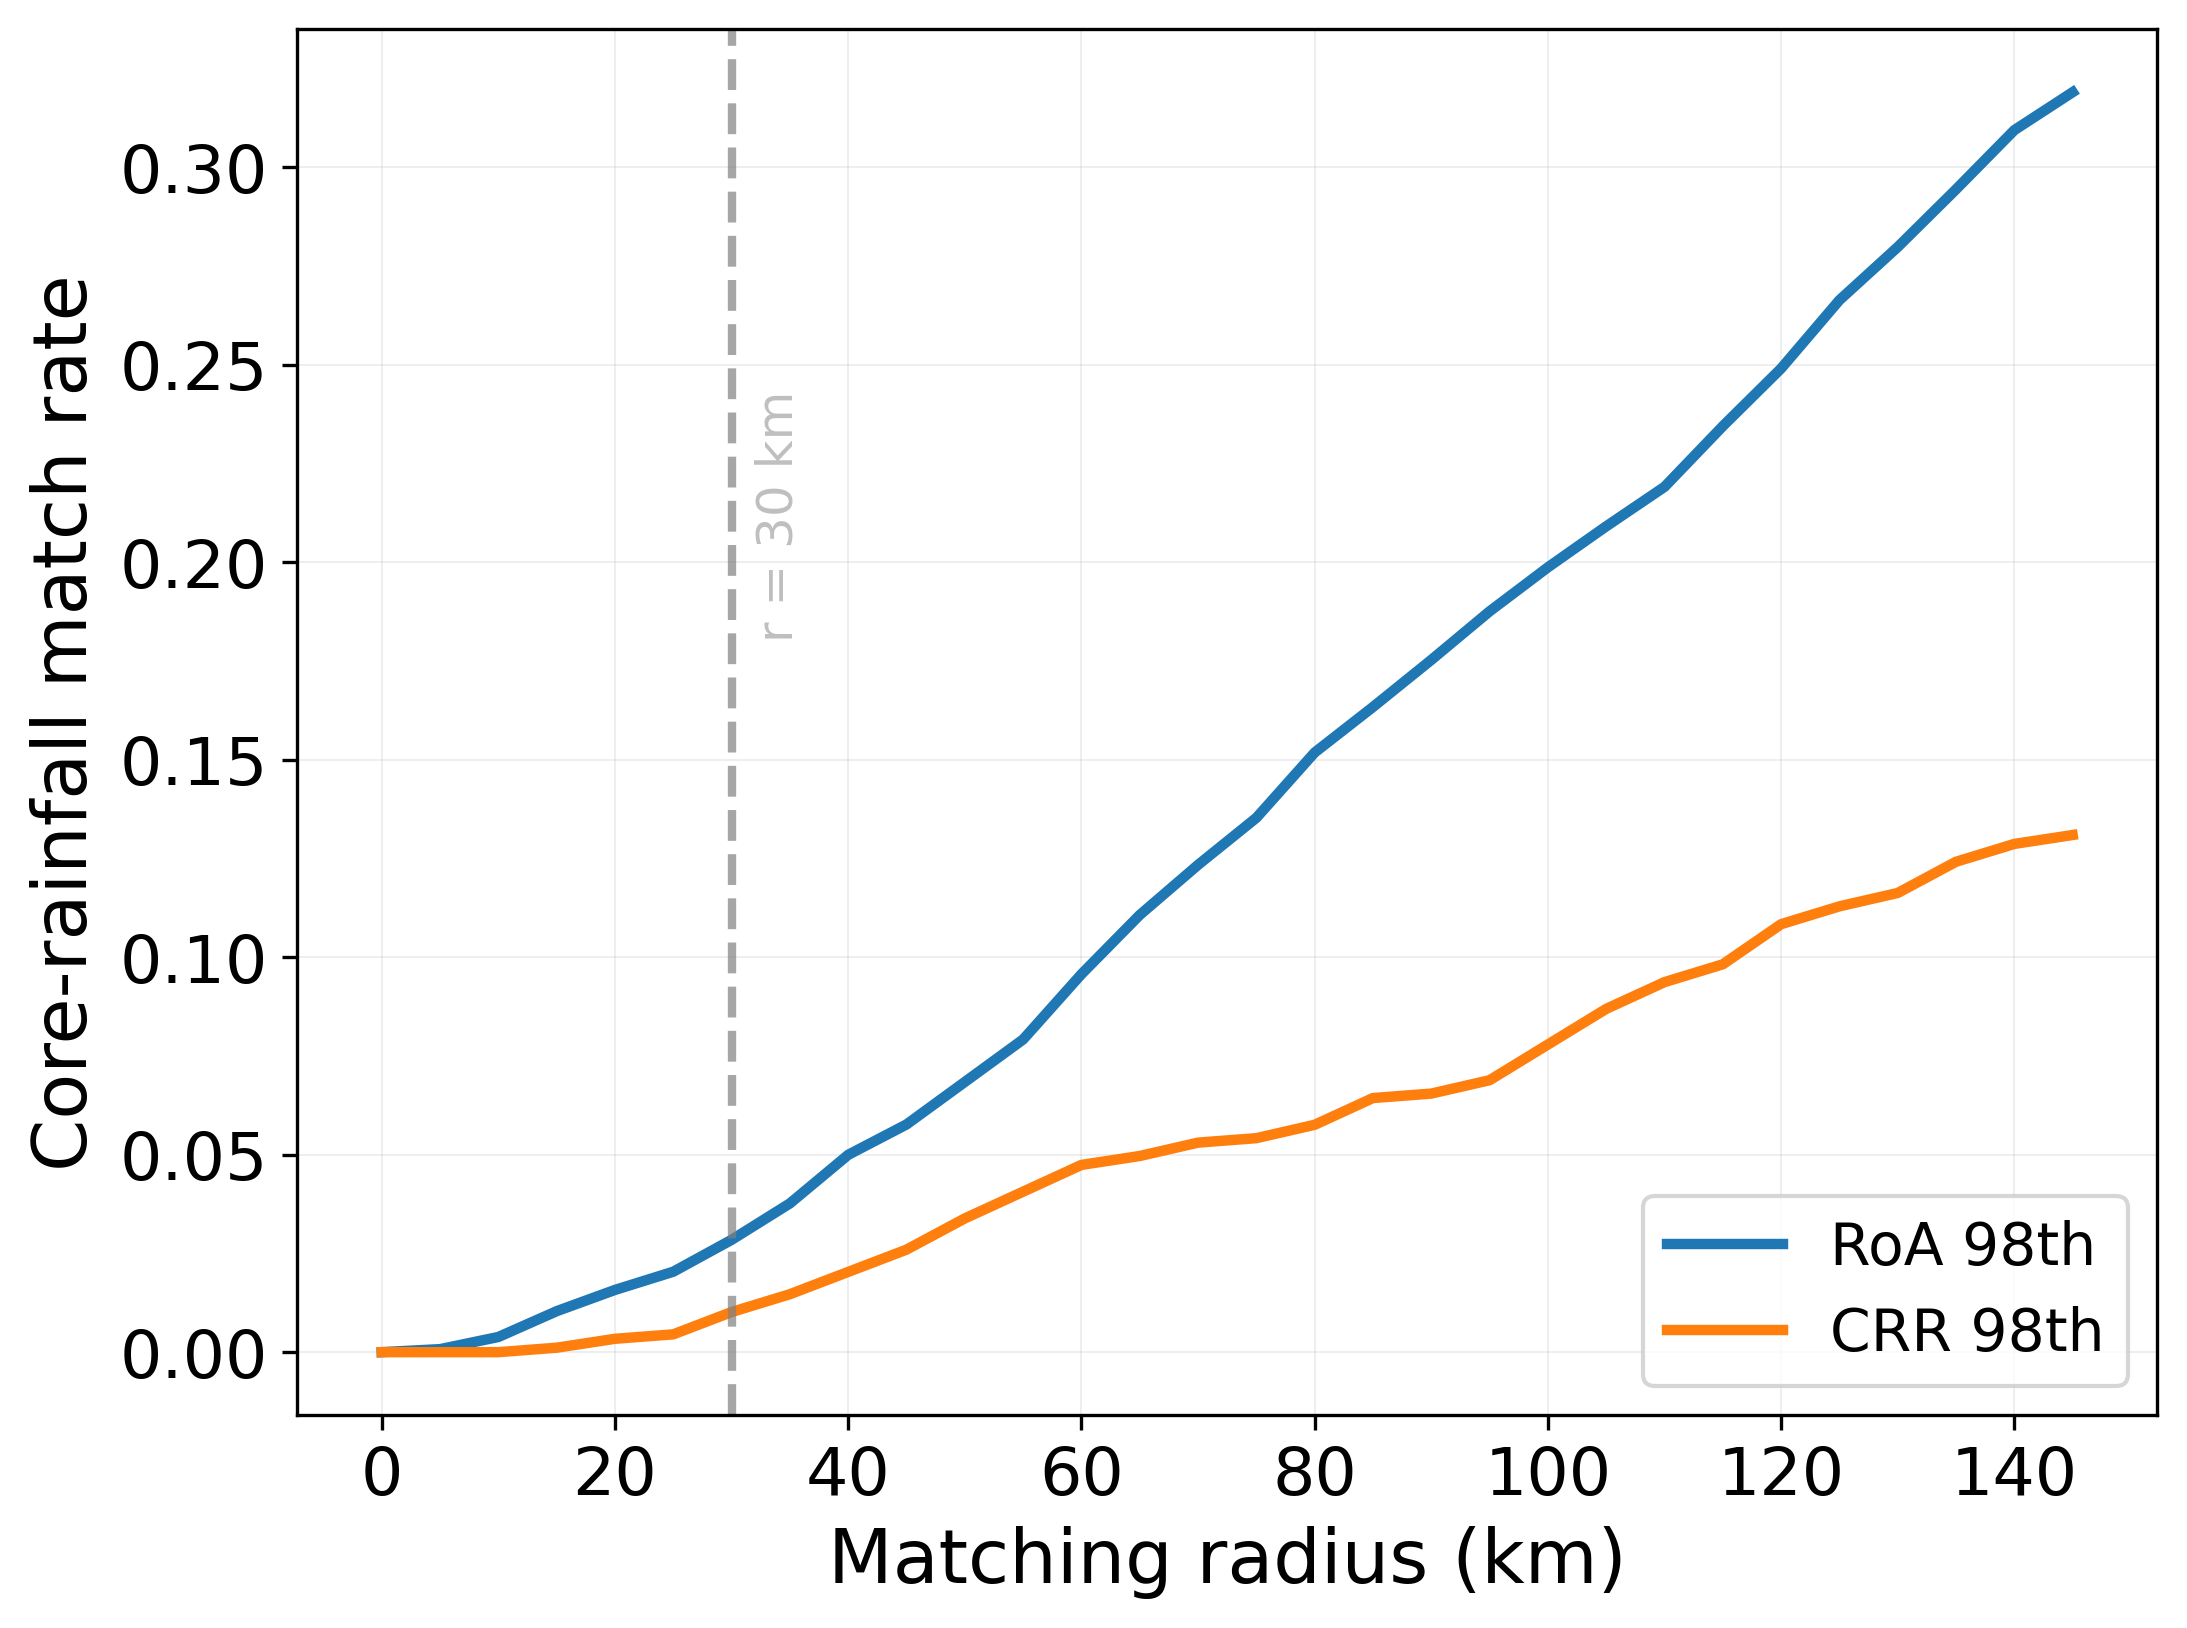

In [ ]:
radii = np.arange(0, 150, 5)

rates_roa = [np.mean(dist_core_roa <= r) for r in radii]
rates_crr = [np.mean(dist_core_crr <= r) for r in radii]

plt.figure(figsize=(8, 6), dpi=300)

plt.plot(radii, rates_roa, linewidth=2.5, label="RoA 98th")
plt.plot(radii, rates_crr, linewidth=2.5, label="CRR 98th")

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Core-rainfall match rate", fontsize=18)

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    32,
    0.18,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom", 
    alpha=0.5
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()

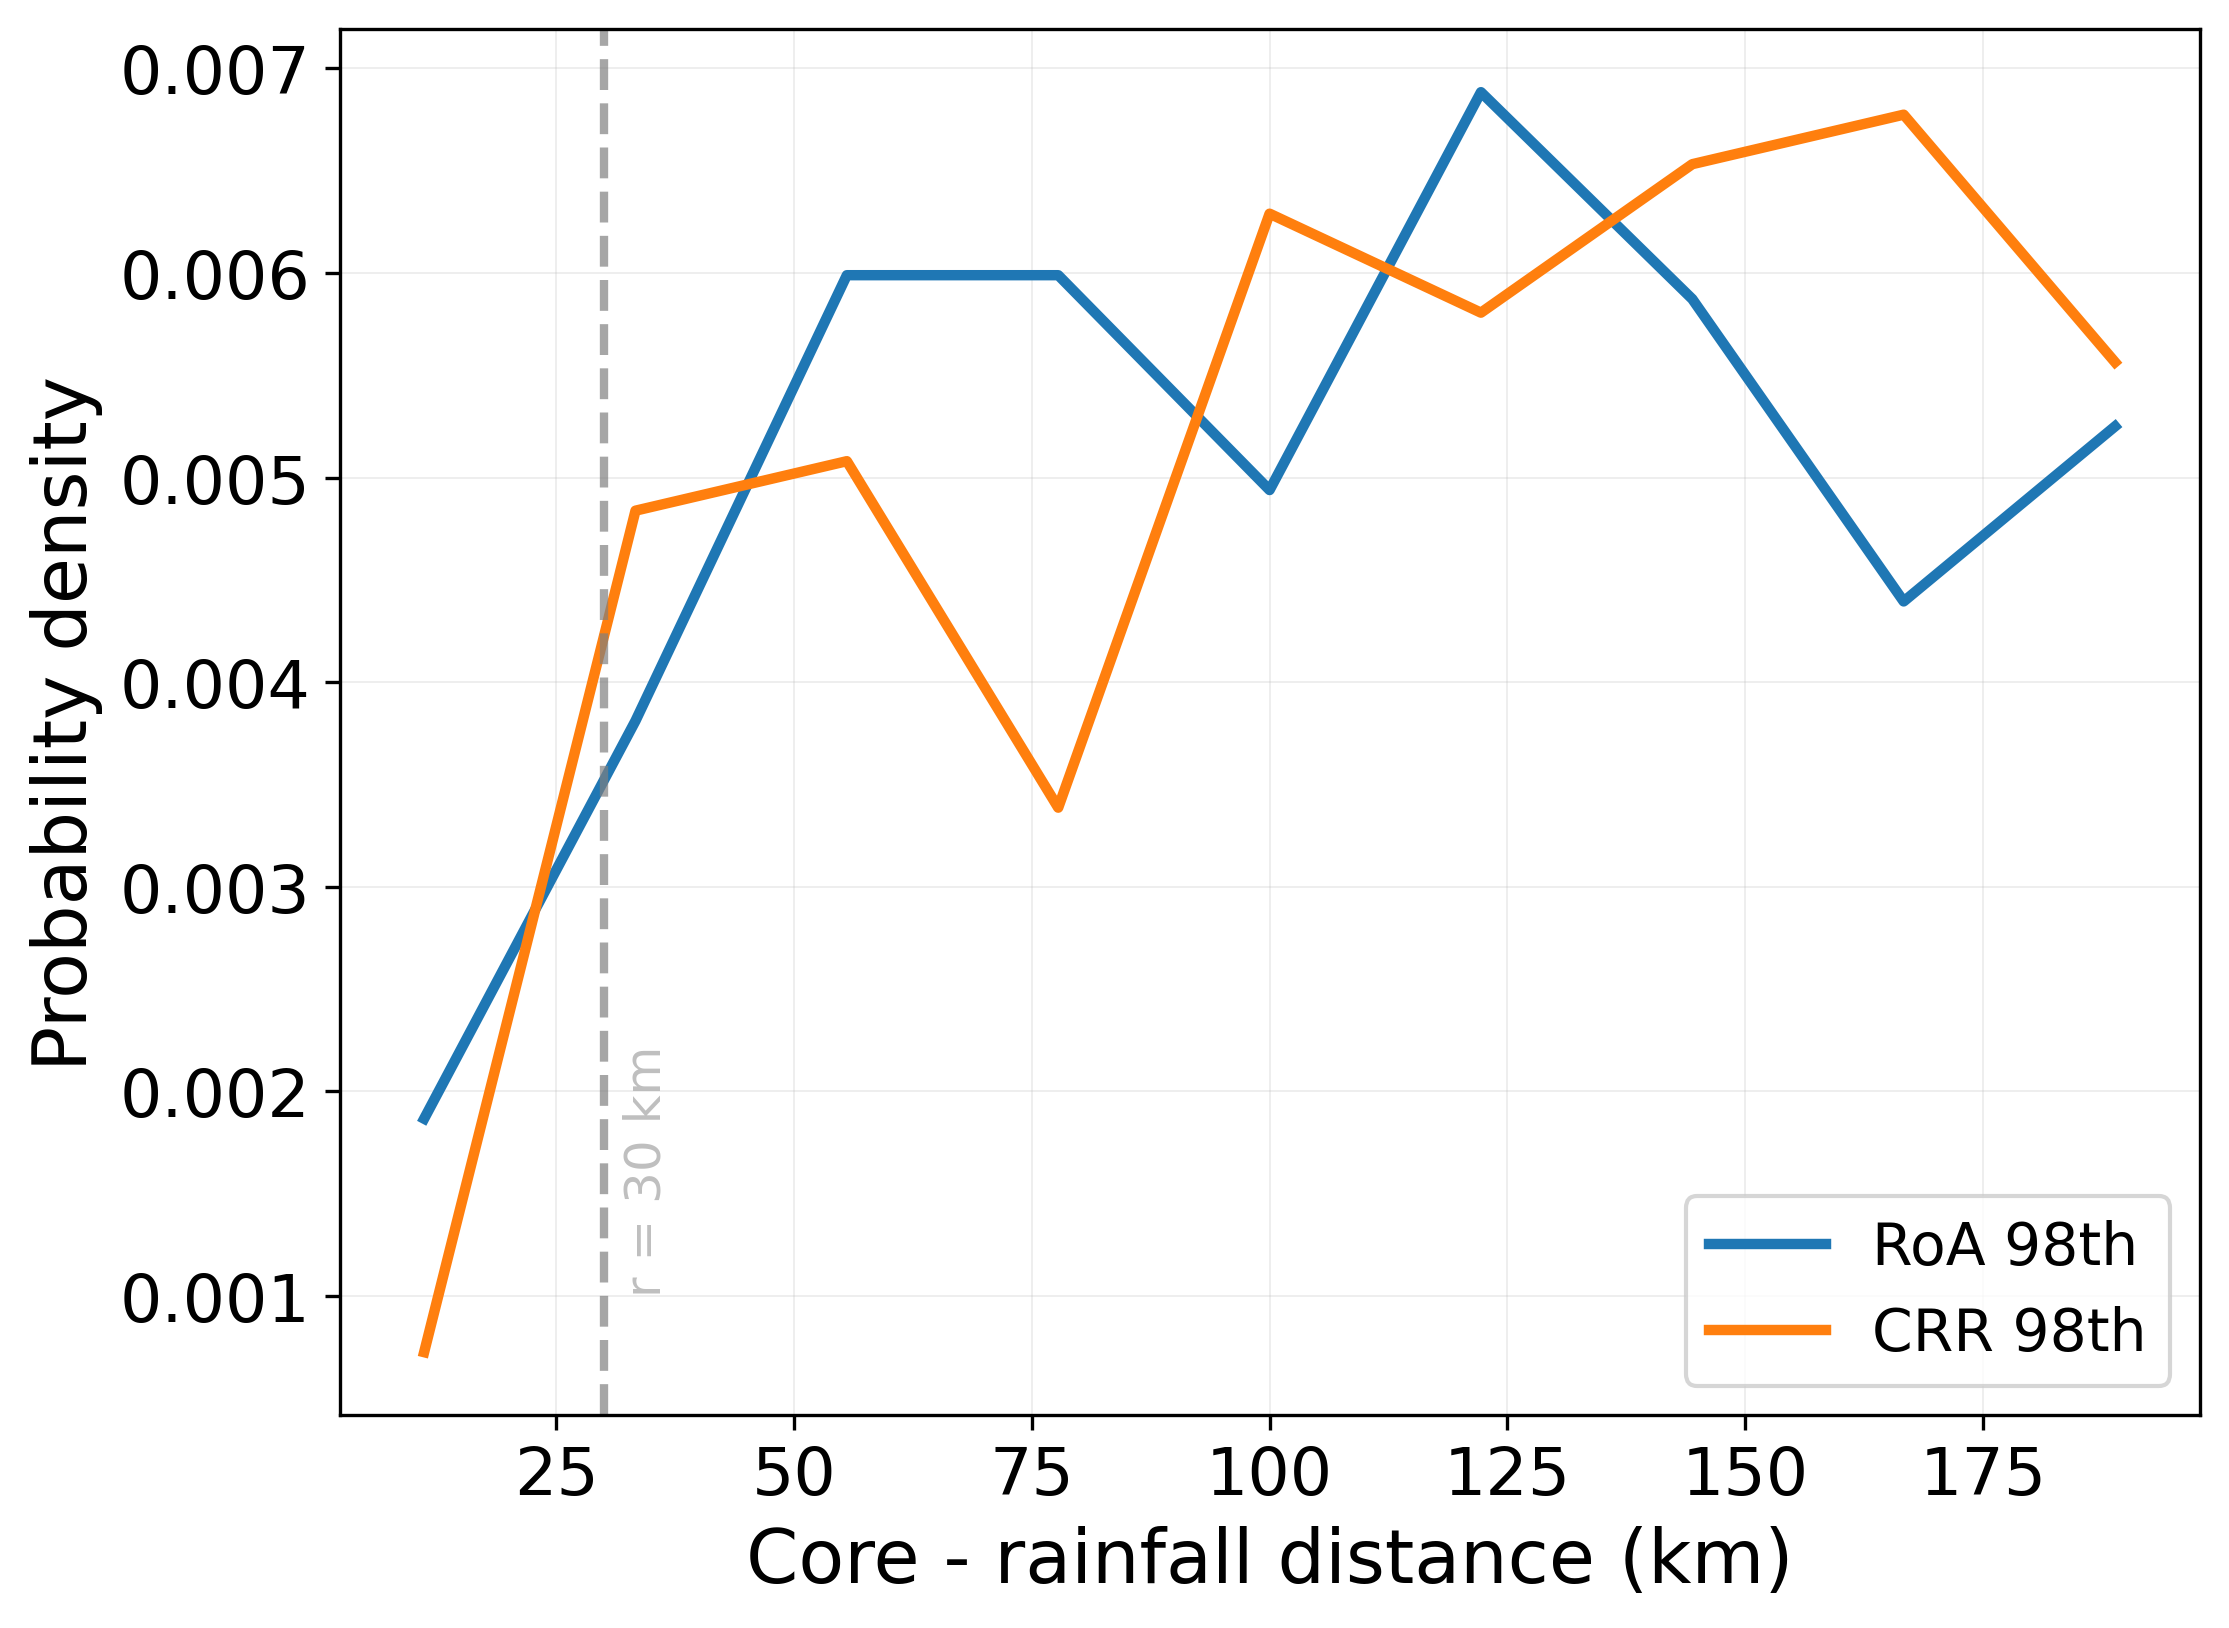

In [36]:
# Distance arrays already computed
# dist_core_roa
# dist_core_crr

max_plot_radius = 200

dist_roa = dist_core_roa[dist_core_roa <= max_plot_radius]
dist_crr = dist_core_crr[dist_core_crr <= max_plot_radius]

bins = np.linspace(0, max_plot_radius, 10)

hist_roa, bin_edges = np.histogram(dist_roa, bins=bins, density=True)
hist_crr, _ = np.histogram(dist_crr, bins=bins, density=True)

bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(8,6))

plt.plot(bin_centres, hist_roa, linewidth=2.5, label="RoA 98th")
plt.plot(bin_centres, hist_crr, linewidth=2.5, label="CRR 98th")

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    32,
    0.001,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom", 
    alpha=0.5
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Core - rainfall distance (km)", fontsize=18)
plt.ylabel("Probability density", fontsize=18)

plt.grid(True, linewidth=0.1)

plt.show()

In [24]:
set(cores.time.unique()) - set(roa.time.unique())

set()

In [25]:
roa.columns

Index(['label', 'lat_centroid', 'lon_centroid', 'lat_min', 'lat_max',
       'lon_min', 'lon_max', 'size', 'n_pix', 'mean_roa', 'max_roa',
       'elongation', 'eccentricity', 'time', 'year', 'month', 'day', 'hour'],
      dtype='object')

In [26]:
crr.columns

Index(['label', 'lat_centroid', 'lon_centroid', 'lat_min', 'lat_max',
       'lon_min', 'lon_max', 'size', 'n_pix', 'mean_crr', 'max_crr',
       'elongation', 'eccentricity', 'time', 'year', 'month', 'day', 'hour'],
      dtype='object')

In [27]:
print(len(cores["time"].unique()))
print(len(roa["time"].unique()))
print(len(crr["time"].unique()))

print(len(set(cores["time"]) & set(roa["time"])))
print(len(set(cores["time"]) & set(crr["time"])))

6277
6277
1591
6277
1589


In [28]:
print(np.median(dist_core_roa))
print(np.median(dist_core_crr))

231.08709698879562
406.56598210021303
